# Sección 3 – exploración de los datos
**Proyecto:** Cotizador de fletes

En esta sección presentamos los datos con los que trabajamos: de dónde vienen, qué contiene cada columna y qué tan limpios están. Al final mostramos las primeras gráficas de los costos de flete.

In [ ]:
# --- Preparación ---
# Cargamos las librerías, leemos el CSV con las órdenes y la hoja Diccionario del Excel,
# mostramos el tamaño de la tabla y las primeras 5 filas.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 90)

df = pd.read_csv("C:\\Users\\isabe\\Downloads\\cotizador-fletes\\data\\ordenes_limpias.csv")
dicc = pd.read_excel("C:\\Users\\isabe\\Downloads\\cotizador-fletes\\data\\ordenes_limpias.xlsx", sheet_name="Diccionario")
print(df.shape)
df.head()

(5608, 30)


,waybill,company,customer_id,order_date,order_year,order_month,origin,destination_port,delivery_dest,currency,container_type,total_skids,lead_time_days,ocean_carrier,land_carrier,base_ocean_rate,invoice_rate_markup,ocean_cost,land_cost,ocean_surcharge,final_surcharge,land_freight_invoiced,surcharge_discount,land_freight_discount,ocean_value_change,original_destination,original_ocean_value,delivery_state,ocean_cost_per_skid,land_cost_per_skid
0,27410,1,463,2024-01-02,2024,1,Shanghai,"Los Angeles, CA","Santa Fe Springs, CA",USD,40FT,11.04295,34.0,Northstar Express,MAV Transportation,2841.5,1.3,2713.92,784.36,312.56,0.0,1019.67,0.0,0.0,CutOff,NaN,NaN,CA,245.760417,71.028122
1,27412,1,245,2024-01-02,2024,1,Shanghai,"Portland, OR","Jefferson OR United States, of",USD,LCL,1.25000,55.0,Northstar Express,Northstar Express,2000.0,1.3,1089.00,445.00,-152.00,0.0,578.50,0.0,0.0,NaN,NaN,NaN,of,871.200000,356.000000
2,27413,1,20,2024-01-02,2024,1,Shanghai,"Los Angeles, CA","NIPOMO, CA",USD,40FT,21.00000,69.0,Northstar Express,Northstar Express,3000.0,1.2,3716.14,1450.00,1475.14,0.0,1740.00,0.0,0.0,NaN,NaN,NaN,CA,176.959048,69.047619
3,27414,1,20,2024-01-02,2024,1,Shanghai,"Los Angeles, CA","NIPOMO, CA",USD,40FT,22.00000,48.0,Northstar Express,Northstar Express,3400.0,1.2,3816.14,1450.00,1175.14,0.0,1740.00,0.0,0.0,NaN,NaN,NaN,CA,173.460909,65.909091
4,27415,1,843,2024-01-02,2024,1,Shanghai,"Chicago, IL","Oxford , PA",USD,40FT,0.44155,55.0,Northstar Express,Navegate Land,86.4,1.3,144.04,345.88,74.03,0.0,449.64,0.0,0.0,NaN,NaN,NaN,PA,326.214472,783.331446


## 3.1 ¿De dónde salen los datos?

Unimos dos reportes internos de la empresa: el **reporte IMCS** y el **Shipping Schedule**. Los cruzamos usando el número de **Waybill**, de modo que cada fila es una orden con la información de los dos reportes.

En total tenemos **5.608 órdenes y 30 columnas**, creadas entre enero de 2024 y julio de 2026. Son envíos que salen por barco desde China (Shanghai o Nanjing) hacia puertos de Estados Unidos y Canadá, y que después siguen por tierra hasta la ciudad del cliente.

Para proteger la información, los clientes y las compañías aparecen con códigos en vez de nombres. También quitamos notas, márgenes, ventas y programas.

In [5]:
# --- Resumen general ---
# Contamos órdenes y columnas, buscamos la primera y la última fecha,
# y vemos cuántas órdenes hay por año y por puerto de origen.
print(f"Órdenes: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
fechas = pd.to_datetime(df["order_date"], errors="coerce")
print("Periodo:", fechas.min().date(), "a", fechas.max().date())
print()
print("Órdenes por año:"); print(df["order_year"].value_counts().sort_index().to_string())
print()
print("Origen:"); print(df["origin"].value_counts().to_string())

Órdenes: 5,608  |  Columnas: 30
Periodo: 2024-01-02 a 2026-07-22

Órdenes por año:
order_year
2024    2267
2025    2592
2026     749

Origen:
origin
Shanghai    4746
Nanjing      862


## 3.2 ¿Qué hay en cada columna?

La hoja Diccionario del Excel explica las 30 columnas. Para el modelo lo más importante es separar lo que **sabemos al momento de cotizar** de lo que **solo se sabe después del envío**:

- **Variables (13):** lo que conocemos al cotizar, como el cliente, la fecha, el puerto de destino, la ciudad de entrega, la moneda, el tipo de contenedor, el número de skids y los días de anticipación.
- **Reglas de negocio (2):** la tarifa base del flete marítimo 'base_ocean_rate' y el mark up del flete terrestre 'invoice_rate_markup'. También se conocen al cotizar.
- **Objetivos (4):** lo que queremos predecir: el costo real del flete marítimo 'ocean_cost' y del terrestre 'land_cost', en total y por skid.
- **Verificación (5) y descriptivas (3):** surcharges, montos facturados, descuentos y datos de cut off. Solo existen después del envío, así que nos sirven para revisar y analizar, pero no entran al modelo.
- **Identificador (1):** el 'waybill' para unir y rastrear órdenes.
- **Por confirmar (2):** la naviera y el transportista terrestre. Puede que se asignen después de cotizar; si es así, no podríamos usarlos.



In [6]:
# --- Diccionario resumido ---
# Agrupamos las columnas según su tipo (variable, objetivo, verificación, etc.)
# y mostramos cuántas hay de cada tipo y si se conocen al cotizar.
orden_tipos = ["Variable", "Variable (revisar)", "Regla de negocio", "Objetivo",
               "Verificación", "Descriptiva", "Identificador"]
dicc["Tipo"] = pd.Categorical(dicc["Tipo"], categories=orden_tipos, ordered=True)

resumen = (dicc.sort_values("Tipo")
               .groupby("Tipo", observed=True)
               .agg(n_columnas=("Columna", "size"),
                    columnas=("Columna", lambda x: ", ".join(x)),
                    se_conoce_al_cotizar=("¿Se conoce al cotizar?", "first")))
resumen

,n_columnas,columnas,se_conoce_al_cotizar
Tipo,,,
Variable,13,"delivery_dest, company, customer_id, order_date, order_year, order_month, origin, dest...",Sí
Variable (revisar),2,"land_carrier, ocean_carrier",Por confirmar: puede asignarse después (posible leakage)
Regla de negocio,2,"invoice_rate_markup, base_ocean_rate",Sí
Objetivo,4,"land_cost, land_cost_per_skid, ocean_cost_per_skid, ocean_cost","No, se conoce después"
Verificación,5,"ocean_surcharge, final_surcharge, land_freight_invoiced, surcharge_discount, land_frei...","No, se conoce después"
Descriptiva,3,"ocean_value_change, original_destination, original_ocean_value","No, se conoce después"
Identificador,1,waybill,No usar en el modelo


In [7]:
# --- Revisión ---
# Comprobamos que todas las columnas del CSV aparezcan en el Diccionario.
faltan = set(df.columns) - set(dicc["Columna"])
print("Columnas del CSV que no están en el Diccionario:", faltan or "ninguna")

Columnas del CSV que no están en el Diccionario: ninguna


## 3.3 ¿Qué tan limpios están los datos?

### Datos faltantes

In [8]:
# --- Datos faltantes ---
# Contamos los vacíos de cada columna, calculamos su porcentaje
# y mostramos solo las columnas que tienen al menos uno.
falt = df.isna().sum().to_frame("faltantes")
falt["%"] = (falt["faltantes"] / len(df) * 100).round(2)
falt = falt.join(dicc.set_index("Columna")["Tipo"])
falt[falt["faltantes"] > 0].sort_values("faltantes", ascending=False)

,faltantes,%,Tipo
original_destination,5516,98.36,Descriptiva
original_ocean_value,5514,98.32,Descriptiva
ocean_value_change,5353,95.45,Descriptiva
delivery_dest,136,2.43,Variable
delivery_state,136,2.43,Variable
land_carrier,104,1.85,Variable (revisar)
ocean_carrier,97,1.73,Variable (revisar)
lead_time_days,11,0.20,Variable


Casi todos los faltantes tienen explicación. Las tres columnas con más vacíos (más del 95 %) son las del cut off, y es normal: solo se llenan cuando la orden cambió de puerto o de tipo de envío.

En las variables que sí usaríamos para cotizar faltan muy pocos datos: la ciudad y el estado de entrega (2,4 %), la naviera y el transportista (menos del 2 %) y los días de anticipación (11 órdenes).

También vimos direcciones mal escritas. Por ejemplo, una orden tiene como destino *"Jefferson OR United States, of"* y su estado quedó como **"of"**. Antes de usar el estado de entrega en el modelo hay que corregir estos casos.

### Casos que hay que revisar

In [9]:
# --- Casos especiales ---
# Contamos las órdenes con menos de 1 skid y con flete en cero,
# y vemos cómo se reparten las órdenes por moneda y por tipo de contenedor.
n = len(df)
menos_1_skid = (df["total_skids"] < 1).sum()
land_cero    = (df["land_cost"] == 0).sum()
ocean_cero   = (df["ocean_cost"] == 0).sum()
print(f"Órdenes con menos de 1 skid:   {menos_1_skid:>5} ({menos_1_skid/n:.1%})")
print(f"Órdenes con land freight = 0:  {land_cero:>5} ({land_cero/n:.1%})")
print(f"Órdenes con ocean freight = 0: {ocean_cero:>5} ({ocean_cero/n:.1%})")
print()
print("Moneda de las órdenes:"); print(df["currency"].value_counts().to_string())
print()
print("Tipo de contenedor:"); print(df["container_type"].value_counts().to_string())

Órdenes con menos de 1 skid:      50 (0.9%)
Órdenes con land freight = 0:    128 (2.3%)
Órdenes con ocean freight = 0:     0 (0.0%)

Moneda de las órdenes:
currency
USD    3889
CAD    1719

Tipo de contenedor:
container_type
40FT    5542
LCL       34
20FT      32


In [10]:
# --- Flete terrestre en cero por tipo de contenedor ---
# sum = cuántas órdenes tienen land_cost en 0; mean = qué proporción representan.
df.assign(land_cero=df["land_cost"] == 0).groupby("container_type")["land_cero"].agg(["sum", "mean"]).round(3)

,sum,mean
container_type,,
20FT,1,0.031
40FT,123,0.022
LCL,4,0.118


**Las monedas no se pueden mezclar.** El 69 % de las órdenes está en dólares estadounidenses (USD) y el 31 % en dólares canadienses (CAD). Los costos vienen en la moneda de cada orden, así que siempre los comparamos por separado. Casi siempre la moneda depende del país del puerto: los puertos canadienses (Toronto, Montreal, Vancouver) facturan en CAD y los de Estados Unidos en USD.

Además, casi todas las órdenes van en contenedor de 40 pies (5.542). Solo hay 34 envíos LCL (carga consolidada) y 32 en contenedor de 20 pies, así que tenemos pocos datos para predecir bien esos dos casos.

**Órdenes raras:**
- **50 órdenes (0,9 %) tienen menos de 1 skid.** Son envíos muy pequeños y, al dividir el costo entre los skids, el costo por skid se altera. Por eso las dejamos fuera del análisis por skid.
- **128 órdenes (2,3 %) tienen flete terrestre en cero.** Puede que el cliente haya recogido la carga en el puerto. Pasa más en los envíos LCL (12 %) que en los de 40 pies (2 %).
- **Ninguna orden tiene flete marítimo en cero.**

### Costo por skid y valores extremos

Para comparar órdenes de distinto tamaño usamos el **costo por skid** 'ocean_cost_per_skid' y 'land_cost_per_skid', solo en órdenes con al menos 1 skid. Consideramos extremo un valor que pasa el límite habitual de Q3 + 1,5 × IQR.

In [11]:
# --- Valores extremos ---
# Nos quedamos con las órdenes de al menos 1 skid y, para cada moneda,
# calculamos mediana, percentil 95, máximo y cuántos valores pasan el límite IQR.
base = df[df["total_skids"] >= 1].copy()

def extremos(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    return pd.Series({"órdenes": len(s), "mediana": s.median(), "p95": s.quantile(.95),
                      "máximo": s.max(), "límite IQR": lim, "n extremos": (s > lim).sum()})

filas = {}
for mon, g in base.groupby("currency"):
    filas[(mon, "Ocean por skid")] = extremos(g["ocean_cost_per_skid"])
    filas[(mon, "Land por skid (sin ceros)")] = extremos(g.loc[g["land_cost"] > 0, "land_cost_per_skid"])
pd.DataFrame(filas).T.round(1)

órdenes  mediana    p95  máximo  límite IQR  \
CAD Ocean por skid              1697.0    311.5  590.3  1675.9       634.1   
    Land por skid (sin ceros)   1672.0     53.9  396.4  1154.5       244.4   
USD Ocean por skid              3861.0    231.8  448.5  4300.0       538.3   
    Land por skid (sin ceros)   3759.0     69.5  464.4  3500.0       397.7   

                               n extremos  
CAD Ocean por skid                   41.0  
    Land por skid (sin ceros)       192.0  
USD Ocean por skid                   31.0  
    Land por skid (sin ceros)       286.0

## 3.4 Gráficas

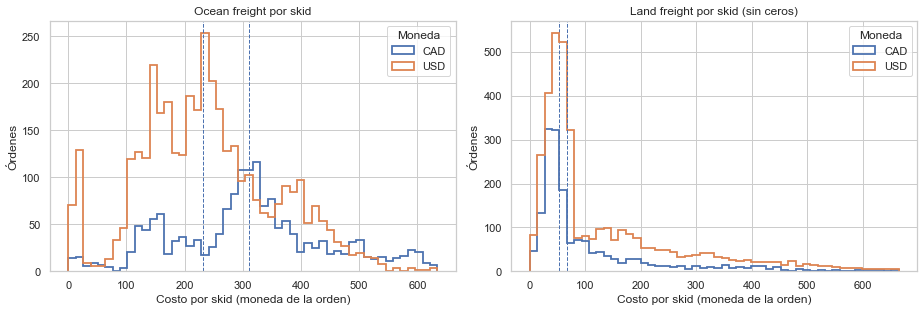

In [13]:
# --- Gráfica 1: distribución del costo por skid ---
# Un histograma para el flete marítimo y otro para el terrestre, separados por moneda.
# Las líneas punteadas marcan la mediana de cada moneda.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, colname, titulo in [
    (axes[0], "ocean_cost_per_skid", "Ocean freight por skid"),
    (axes[1], "land_cost_per_skid",  "Land freight por skid (sin ceros)"),
]:
    d = base if colname == "ocean_cost_per_skid" else base[base["land_cost"] > 0]
    d = d[d[colname] <= d[colname].quantile(.99)]  # se recorta el 1% más alto para ver la forma
    bins = np.linspace(d[colname].min(), d[colname].max(), 51)
    for mon, g in d.groupby("currency"):
        ax.hist(g[colname], bins=bins, histtype="step", linewidth=1.8, label=mon)
        ax.axvline(g[colname].median(), ls="--", linewidth=1,
                   color=ax.lines[-1].get_color() if ax.lines else None)
    ax.set_title(titulo); ax.set_xlabel("Costo por skid (moneda de la orden)"); ax.set_ylabel("Órdenes")
    ax.legend(title="Moneda")
plt.tight_layout()
plt.savefig("fig_s3_distribucion_por_skid.png", dpi=150)
plt.show()

- **Flete marítimo:** en USD, la mayoría de las órdenes cuesta entre 100 y 300 por skid (mediana de 232). En CAD los valores son más altos y están más repartidos (mediana de 312).
- **Flete terrestre:** casi todas las órdenes cuestan menos de 100 por skid (mediana de 70 en USD y 54 en CAD), pero hay una cola larga de órdenes mucho más caras. Por eso el flete terrestre tiene muchos más valores extremos que el marítimo.

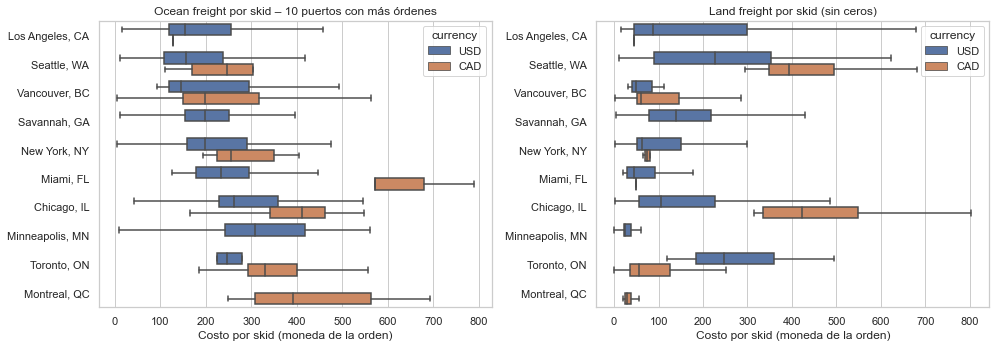

ordenes  ocean_mediana  land_mediana
destination_port currency                                      
Chicago, IL      CAD             6          411.0         423.0
                 USD           829          262.0         105.0
Los Angeles, CA  CAD             1          128.0          44.0
                 USD           574          155.0          85.0
Miami, FL        CAD             3          572.0          50.0
                 USD           180          234.0          44.0
Minneapolis, MN  USD           155          307.0          24.0
Montreal, QC     CAD           180          392.0          30.0
New York, NY     CAD            13          255.0          74.0
                 USD           377          198.0          64.0
Savannah, GA     USD           717          199.0         140.0
Seattle, WA      CAD             8          248.0         393.0
                 USD           152          156.0         227.0
Toronto, ON      CAD           843          329.0          56.0
                 USD             9          246.0         246.0
Vancouver, BC    CAD           605          198.0          58.0
                 USD            31          145.0          49.0

In [14]:
# --- Gráfica 2: costo por skid según el puerto de destino ---
# Tomamos los 10 puertos con más órdenes y los ordenamos del más barato al más caro.
# Las cajas muestran dónde está la mitad de las órdenes; la línea del centro es la mediana.
# Al final, una tabla con el número de órdenes y la mediana por puerto y moneda.
top = base["destination_port"].value_counts().head(10).index
sub = base[base["destination_port"].isin(top)]
orden = sub.groupby("destination_port")["ocean_cost_per_skid"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=sub, y="destination_port", x="ocean_cost_per_skid", hue="currency",
            order=orden, ax=axes[0], showfliers=False)
axes[0].set_title("Ocean freight por skid – 10 puertos con más órdenes")
sns.boxplot(data=sub[sub["land_cost"] > 0], y="destination_port", x="land_cost_per_skid", hue="currency",
            order=orden, ax=axes[1], showfliers=False)
axes[1].set_title("Land freight por skid (sin ceros)")
for ax in axes: ax.set_xlabel("Costo por skid (moneda de la orden)"); ax.set_ylabel("")
plt.tight_layout()
plt.savefig("fig_s3_costo_por_puerto.png", dpi=150)
plt.show()

(sub.groupby(["destination_port", "currency"])
    .agg(ordenes=("ocean_cost_per_skid", "size"),
         ocean_mediana=("ocean_cost_per_skid", "median"),
         land_mediana=("land_cost_per_skid", "median"))
    .round(0))

El costo cambia bastante según el puerto, así que el puerto de destino va a ser una variable importante para el modelo.

- **Flete marítimo:** Los Angeles y Seattle son los más baratos (mediana de unos 155 USD por skid). Minneapolis (307 USD) y Montreal (392 CAD) son los más caros.
- **Flete terrestre:** varía mucho más que el marítimo. Minneapolis y Montreal casi no tienen costo terrestre (unos 25–30 por skid), mientras que Seattle (227 USD) y Savannah (140 USD) son los más altos.
- En algunos puertos hay muy pocas órdenes en la otra moneda, como Miami en CAD (3 órdenes) o Toronto en USD (9). Esas cajas no son confiables.

## Conclusiones de la sección 3

- Tenemos **5.608 órdenes** entre enero de 2024 y julio de 2026. Casi todas salen de Shanghai (85 %) y van en contenedor de 40 pies (99 %).
- Los datos están **bastante completos**. Los faltantes grandes son esperados (columnas de cut off) y en las variables útiles faltan menos del 2,5 %. Sí hay que corregir algunas direcciones mal escritas.
- Se tendrá cuidado con **50 órdenes con menos de 1 skid** y **128 con flete terrestre en cero**.
- **USD y CAD se van a tratar por separado.** Prevenir confunsión de resultados y unidades o convertirlos a una sola moneda.
- El costo por skid cambia mucho **según el puerto**, sobre todo en el flete terrestre, que además tiene más valores extremos.